In [ ]:
pip install pulser

# Pulser in a nutshell

The **Sequence** is the central object in Pulser, and is the core of analog quantum computing. It consists of a series of **Pulses**, that are sequentially allocated to **Channels**.


> **Pulse** : A Pulse is defined as the modulation of a signal's **amplitude**, **detuning** and **phase** over time. Those parameters can be defined at each nanosecond.

> **Channel**: The **Channels** are responsible for manipulating the state of the atoms by addressing specific eletronic transitions between two electronic levels. Physically, these consists of electromagnetic radiation sources - most commonly, of lasers.

A **Sequence** is initialised by specifying a **Device** and a **Register**. The **Register** and all the **Pulses** that will be added to the **Channels** of the **Device** in the **Sequence** have to match the physical constraints defined in the **Device**.

> **Register**: A **Register** is a group of atoms trapped in an arbitrary configuration. Each atom holds a specific quantum state encoded in specific eletronic levels. Since they are the carrier of quantum information they are called qubits.

> **Device**: A **Device** defines things like how many atoms a **Register** can hold and in what configurations they can be arranged in; as well as what **Channels** are available and what are the limitations on the **Pulse** parameters when  emmiting a **Pulse** through a **Channel** among others.







# Step 1 - Creating the register

A **Register** object in Pulser defines the positions of the atoms and their names.

There are multiple ways of defining a **Register**:

1.   From **a dictionnary** that associates a name (the key) to a coordinate (the value): this is the most customizable one, but can be quite complex to use when working with many atoms.

2.   From **a list of coordinates**, the naming happens automatically using the list's order and a commong prefix that can be added before each number. It can also automatically centre the entire array around the origin. This is useful when you know exactly where you want the atoms to be placed, but is complex to use if you wan the atoms to follow a pattern.

3.   From **a built-in class methods** to place the atoms following a common array pattern, like square or triangular lattices.

4.   From **a RegisterLayout**, a layout of traps used preliminary to the **Sequence** to trap the atoms before redistributing them into the sites of the **Register**. This is used in some real QPUs that don't allow the definition of a **Register** without a calibrated layout.

5.   From **a MappleRegister**, an abstract **Register** that only stores names without coordinates.




All these options are further detailed in the [**Register** section of Pulser documentation](https://pulser.readthedocs.io/en/stable/apidoc/_autosummary/pulser.register.Register.html).

<font color='Green'>**Activity 1 - Creating a Register**

Create a 2x2 square array with atoms 20 micrometers apart by running the following code:</font>

/usr/local/lib/python3.12/dist-packages/pulser/register/register.py:58: DeprecationWarning: Usage of `int`s or any non-`str`types as `QubitId`s will be deprecated. Define your `QubitId`s as `str`s, prefer setting `prefix='q'` when using classmethods, as that will become the new default once `int` qubit IDs become invalid.
  super().__init__(qubits, **kwargs)


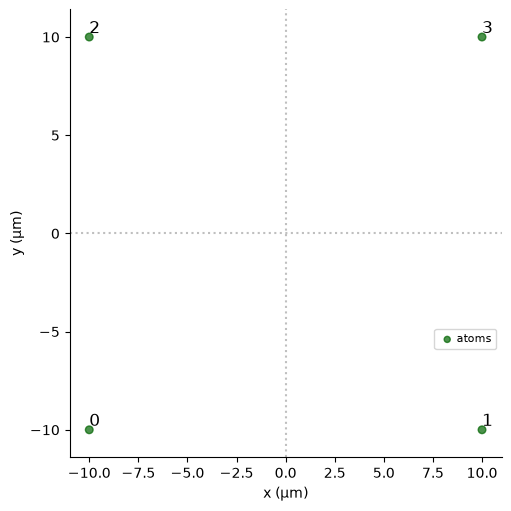

In [2]:
from pulser import Register
reg = Register.square(2, spacing=20) # 2x2 array with atoms placed 20 micrometers apart from each other
reg.draw()

# Step 2 - Initializing the sequence

To create a **Sequence**, you need to provide a **Register** instance and specify the **Device** on which the sequence will be executed. The chosen **Device** will determine the validity of the **Register**.


## Physical devices

For convenience, some examples of typical physical devices are included and can be accessed via ```pulser.devices``` (find the list of the available hysical devices in the [**Devices** section of Pulser documentation](https://pulser.readthedocs.io/en/stable/tutorials/virtual_devices.html).

These devices are instances of the **Device** class. They are constrained by physical considerations and all their parameters are defined. Each QPU has an associated **Device**.

The available devices can be fetched using a remote connection. Have a look at the [**Backed** section of Pulser documentation](https://pulser.readthedocs.io/en/stable/tutorials/virtual_devices.html) to see how to fetch the **Device** associated with the QPU.





<font color='Green'>**Activity 2 - Accessing the specifications of a physical device**</font>

<font color='Green'>As an example, run the following line of code to display the specifications of the so called **AnalogDevice** - an example of the first generation QPU developed at Pasqal, which allows analog control only.</font>

In [3]:
from pulser.devices import AnalogDevice
AnalogDevice.print_specs()

---------------------------
AnalogDevice Specifications
---------------------------
A realistic device for analog sequence execution.

Register parameters:
 - Dimensions: 2D
 - Maximum number of atoms: 80
 - Maximum distance from origin: 38 µm
 - Minimum distance between neighbouring atoms: 5 μm

Layout parameters:
 - Requires layout: Yes
 - Accepts new layout: Yes
 - Minimal number of traps: 1
 - Minimum layout filling fraction: 0.0
 - Maximum layout filling fraction: 0.5

Device parameters:
 - Rydberg level: 60
 - Ising interaction coefficient: 865723.02
 - Channels can be reused: No
 - Supported bases: ground-rydberg
 - Supported states: r, g
 - SLM Mask: No
 - Maximum sequence duration: 6000 ns
 - Maximum number of runs: 2000

Channels:
 - 'rydberg_global': Rydberg(addressing='Global',
        max_abs_detuning=125.66370614359172,
        max_amp=12.566370614359172,
        min_retarget_interval=None,
        fixed_retarget_t=None,
        max_targets=None,
        clock_period=4,
 

## Virtual devices

Sometimes, for simulation purposes, we want to perform the computations on a more permissive device, a device that would have more dimensions, atoms,or channel types. This can be done on an emulator that behaves like a physical device. The **VirtualDevice** class is useful for defining such an emulator, a virtual device.

<font color='Green'>**Activity 3 - Converting a Device into a VirtualDevice to change its parameters**.</font>

<font color='Green'>Let’s start by configuring a **VirtualDevice** having the same parameters as the **AnalogDevice** from previous activity.</font>

<font color='Green'>To do this, we use the ```Device.to_virtual()``` method that creates a **VirtualDevice** from a physical one:</font>

In [4]:
VirtualAnalog = AnalogDevice.to_virtual()
print(VirtualAnalog)

VirtualDevice(name='AnalogDevice', dimensions=2, rydberg_level=60, min_atom_distance=5, max_atom_num=80, max_radial_distance=38, interaction_coeff_xy=None, supports_slm_mask=False, min_layout_filling=0.0, max_layout_filling=0.5, optimal_layout_filling=0.45, min_layout_traps=1, max_layout_traps=None, max_sequence_duration=6000, max_runs=2000, requires_layout=True, reusable_channels=False, channel_ids=('rydberg_global',), channel_objects=(Rydberg(addressing='Global', max_abs_detuning=125.66370614359172, max_amp=12.566370614359172, min_retarget_interval=None, fixed_retarget_t=None, max_targets=None, clock_period=4, min_duration=16, max_duration=100000000, min_avg_amp=0, mod_bandwidth=8, custom_phase_jump_time=None, eom_config=RydbergEOM(limiting_beam=<RydbergBeam.RED: 2>, max_limiting_amp=188.49555921538757, intermediate_detuning=2827.4333882308138, controlled_beams=(<RydbergBeam.BLUE: 1>,), mod_bandwidth=40, custom_buffer_time=240, multiple_beam_control=True, blue_shift_coeff=1.0, red_sh

<font color='Green'>Suppose now you want to add an extra dimension to your **VirtualDevice** so as to simulate 3D arrays instead of 2D arrays. The function ```replace()``` from the built-in library **dataclasses** can be used for that. It creates a new **VirtualDevice** having some parameters changed::</font>

In [5]:
from dataclasses import replace
VirtualAnalog3D = replace(VirtualAnalog, dimensions=3)
print(VirtualAnalog3D)

VirtualDevice(name='AnalogDevice', dimensions=3, rydberg_level=60, min_atom_distance=5, max_atom_num=80, max_radial_distance=38, interaction_coeff_xy=None, supports_slm_mask=False, min_layout_filling=0.0, max_layout_filling=0.5, optimal_layout_filling=0.45, min_layout_traps=1, max_layout_traps=None, max_sequence_duration=6000, max_runs=2000, requires_layout=True, reusable_channels=False, channel_ids=('rydberg_global',), channel_objects=(Rydberg(addressing='Global', max_abs_detuning=125.66370614359172, max_amp=12.566370614359172, min_retarget_interval=None, fixed_retarget_t=None, max_targets=None, clock_period=4, min_duration=16, max_duration=100000000, min_avg_amp=0, mod_bandwidth=8, custom_phase_jump_time=None, eom_config=RydbergEOM(limiting_beam=<RydbergBeam.RED: 2>, max_limiting_amp=188.49555921538757, intermediate_detuning=2827.4333882308138, controlled_beams=(<RydbergBeam.BLUE: 1>,), mod_bandwidth=40, custom_buffer_time=240, multiple_beam_control=True, blue_shift_coeff=1.0, red_sh

In fact, there is a **VirtualDevice**, the **MockDevice**, that has all the **Channels** already implemented and imposes no constraints on the number of atoms or the distance between them.

## Sequence initialization

<font color='Green'>**Activity 4 - Initializing a Sequence**.</font>

<font color='Green'>Initialize a **Sequence** object so as to map the 4-qubit **Register** ```reg``` to the **AnalogDevice**. This can be achieved by running the following instruction:</font>

In [6]:
from pulser import Sequence
seq = Sequence(reg, AnalogDevice)

# Step 3 - Declaring the channels that will be used

A **Device** implements some **Channels**, that can be used to modify the state of the atoms via the applications of **Pulses**. As presented in the [convention page](https://pulser.readthedocs.io/en/stable/conventions.html), each **Channel** implements a different Hamiltonian.

The **AnalogDevice** has only one **Channel** available, a ```rydberg_global``` **Channel** that can be used to perform the same operation on all the atoms simultaneously using ground-Rydberg transitions - as needed in analog implementations.

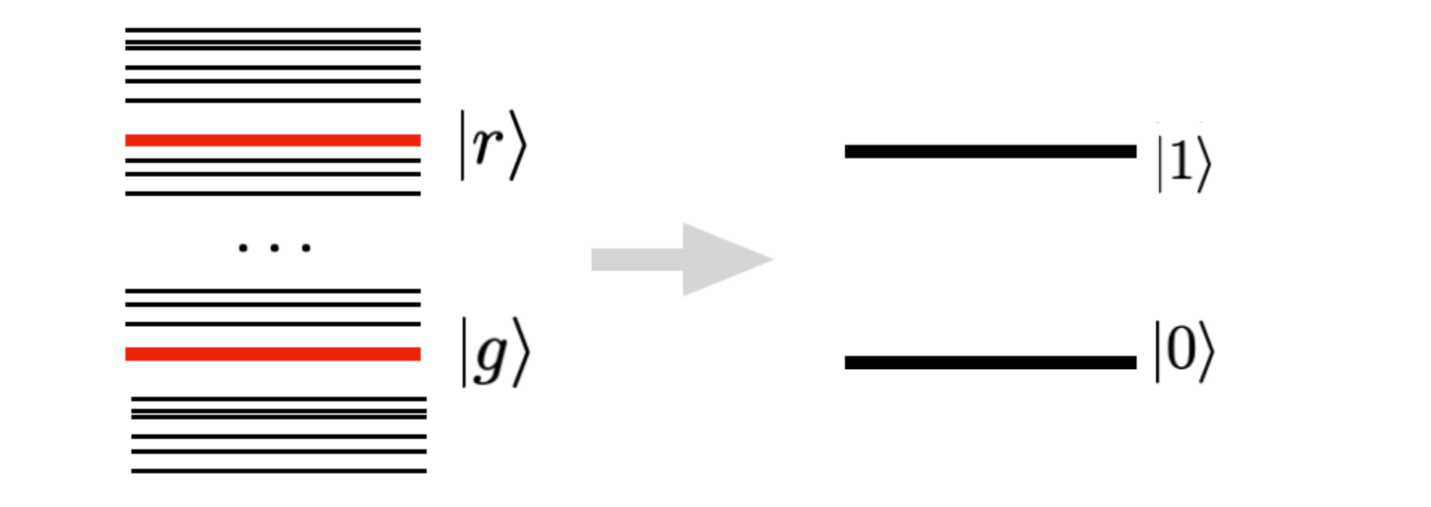

<center>States of the 'ground-rydberg' basis.</center>



In the context of analog (and/or hybrid digital-analog) quantum computing, other **Channels** can be used and are present in the **DigitalAnalogDevice** - a more permissive **Device** allowing both digital and analog implementations, or in the **MockDevice**:


*   The **EOM Mode operation** in a **Rydberg Channel** allows the execution of square pulses with a higher modulation bandwidth to faster the execution of a **Sequence**. It works under very specific conditions, see section on [EOM Mode operation in Pulser documentation](https://pulser.readthedocs.io/en/stable/tutorials/output_mod_eom.html#EOM-Mode-Operation) for more details.

*   The **DMM Channel** can b used to perform local detuning operations on the qubits, even when working with global addressing **Channels**. See the section on [local addressability with DMM in Pulser documentation](https://pulser.readthedocs.io/en/stable/tutorials/dmm.html) for more details.

*   The **Microwave Channel** can be used to perform analog operation with a different interaction term (*XY* instead of *ZZ* - only available in the **MockDevice**).

We won't introduce here, nor use, the **Channels** for digital quantum computing, the ```raman_local``` and the ```raman_global``` **Channels**, as well as the **Channel** for ideal local addressability when addressing Rydberg transitions: the ```rydberg_local``` channel. This choice is motivated by the fact that, unlike analog quantum algorithms, digital quantum algorithms can only be emulated - at small scale - on current generation Pasqal's neutral atom QPUs. In addition, Pulser will probably not be the user tool for digital quantum computing, but a higher level library.



<font color='Green'>**Activity 5 - Declaring a Channel**.</font>

<font color='Green'>Before declaring a **Channel** for your **Sequence**, suppose you want to inspect what **Channels** are available on the **Device** selected (in our case the **AnalogDevice**). This can be achieved by simply running:</font>

In [7]:
seq.available_channels

{'rydberg_global': Rydberg(addressing='Global', max_abs_detuning=125.66370614359172, max_amp=12.566370614359172, min_retarget_interval=None, fixed_retarget_t=None, max_targets=None, clock_period=4, min_duration=16, max_duration=100000000, min_avg_amp=0, mod_bandwidth=8, custom_phase_jump_time=None, eom_config=RydbergEOM(limiting_beam=<RydbergBeam.RED: 2>, max_limiting_amp=188.49555921538757, intermediate_detuning=2827.4333882308138, controlled_beams=(<RydbergBeam.BLUE: 1>,), mod_bandwidth=40, custom_buffer_time=240, multiple_beam_control=True, blue_shift_coeff=1.0, red_shift_coeff=1.0), propagation_dir=None)}

<font color='Green'>We can see that we only have the ```rydberg_global``` **Channel** available. To be used in the **Sequence**, we have to declare this **Channel** and provide a name for it.</font>

In [8]:
seq.declare_channel('ch0', 'rydberg_global')

<font color='Green'>Note how a declared **Channel** is no longer reported as available:</font>




In [9]:
seq.available_channels

{}

<font color='Green'>At any time, we can also consult which channels were declared, their specifications and the name they were given by calling:</font>

In [10]:
seq.declared_channels

{'ch0': Rydberg(addressing='Global', max_abs_detuning=125.66370614359172, max_amp=12.566370614359172, min_retarget_interval=None, fixed_retarget_t=None, max_targets=None, clock_period=4, min_duration=16, max_duration=100000000, min_avg_amp=0, mod_bandwidth=8, custom_phase_jump_time=None, eom_config=RydbergEOM(limiting_beam=<RydbergBeam.RED: 2>, max_limiting_amp=188.49555921538757, intermediate_detuning=2827.4333882308138, controlled_beams=(<RydbergBeam.BLUE: 1>,), mod_bandwidth=40, custom_buffer_time=240, multiple_beam_control=True, blue_shift_coeff=1.0, red_shift_coeff=1.0), propagation_dir=None)}

# Step 4 - Composing the sequence by adding pulses

Now, what remains is to understand how these **Channels** manipulate the state of the atoms, allowing us to program them effectively. To achieve this, we need to delve into the physics and understand the underlaying Hamiltonian of our atomic system.

## Pulse parameters

Now that we have declared a **Channel**, we can add **Pulses** to this **Channel**. Pulses are defined by three quantities: the amplitude $\Omega(t)$ (in rad/μs), the detuning $\delta(t)$ (in rad/μs) - the difference in between the pulse frequency and the resonant frequency of the atomic transition, and the phase $\phi(t)$ (in rad).



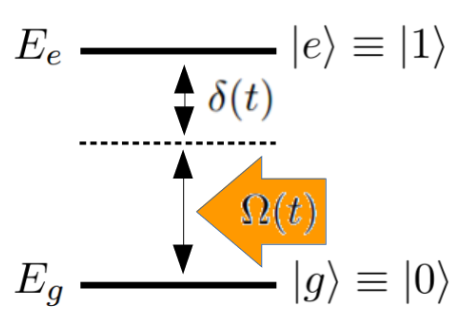

<center> Representation of a two-level transition (g: ground state; e: excited state).</center>

> **Pulse parameters**: A pulse is defined as the modulation of a signal's **amplitude**, **detuning**, and **phase** over a finite duration:
> *   $\Omega(t)$: Rabi frequency (i.e. amplitude) at time $t$
> *  $\delta(t) = \omega(t) - \omega_{ge}$: detuning at time $t$
> * $\phi(t)$: phase at time $t$
> * $\tau$: pulse duration



With Pulser, we can define the value of the amplitude and detuning at each nanosecond using **Waveforms**, while the phase is constant within each pulse.

## Drive Hamiltonian

In quantum physics, the dynamic of a pulse-driven transition in between two-energy levels of an atom is described by the drive Hamiltonian, i.e. each atom "sees" the local operator:

$$H_{D}(t) / \hbar = \dfrac{𝛀 \cdot 𝛔}{2} = \dfrac{\Omega(t)}{2} \cos{(\phi)} \sigma_x - \dfrac{\Omega(t)}{2} \sin{(\phi)} \sigma_y - \dfrac{\delta(t)}{2} \sigma_z$$

where $𝛀(t)$ is a rotation vector, or axis - see explanations below:

$$𝛀(t) = \left[\Omega(t) \cos{(\phi)} , -\Omega(t) \sin{(\phi)}, \delta(t)\right]^{T}$$

and $𝛔$ is the Pauli vector:

$$𝛔 = \left[ \sigma_x, \sigma_y, \sigma_z\right]^{T}$$.

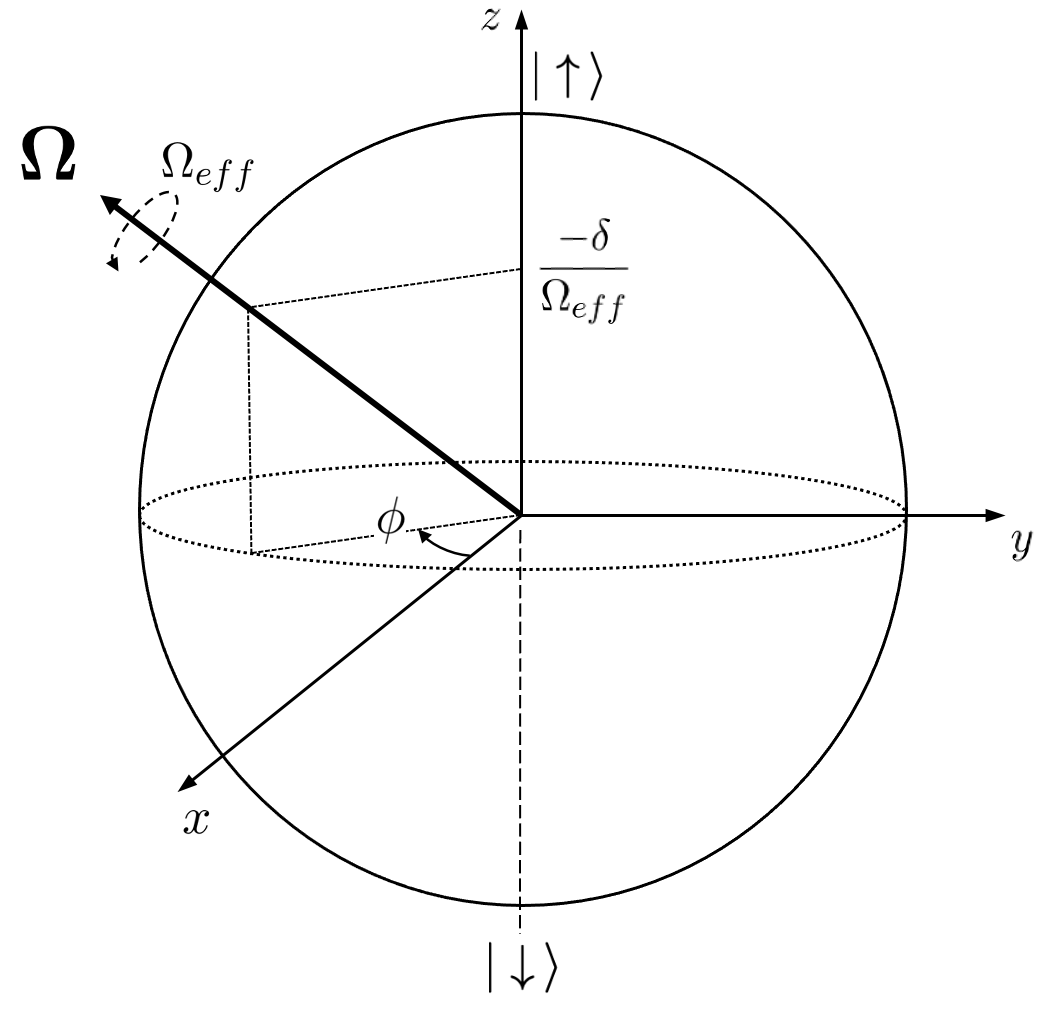

<center> Representation of the drive Hamiltonian's dynamics as a rotation in the Bloch sphere.</center>

Over the pulse duration, this Hamiltonian describes a rotation in the Bloch sphere around the axis $𝛀(t)$ with an angular velocity:

$$\Omega_{eff} = |𝛀| = \sqrt{\Omega^{2} + \delta^{2}}$$

By carefully setting the amplitude, the detuning, and the phase of the pulse, we can then implement a rotation in the desired direction for the desired duration.

## Adding pulses to the sequence

<font color='Green'>**Activity 6 - Applying a bit flip operation on all the qubits from our Register**</font>

<font color='Green'>Assuming the atoms of our **Register** are far away from each other, which is actually the case, one can neglect the dipole-dipole interaction arising when we try to excite atoms close to each other in the Rydberg state (see next lesson on interacting atoms). Thus, the dynamics of our **Register** is fully governed by the drive Hamiltonian we just described.</font>

<font color='Green'> In this context, it is possible to simultaneously excite all the atoms of our Register in the Rydberg state by sending a pulse reproducing (on every atom) the action of a $X$-gate using the ```rydberg_global``` **Channel**.</font>

<font color='Green'> From the Bloch sphere representation, a (global) **Pulse** with zero detuning, zero phase, and an amplitude waveform area of $\pi$ will do exactly that (i.e. a rotation of $\pi$ radiants around the $x$-axis for each atom). </font>

<font color='Green'> Run the following lines of code to define a $\pi$-pulse:</font>


The integral of the waveform is: 3.141592653589794


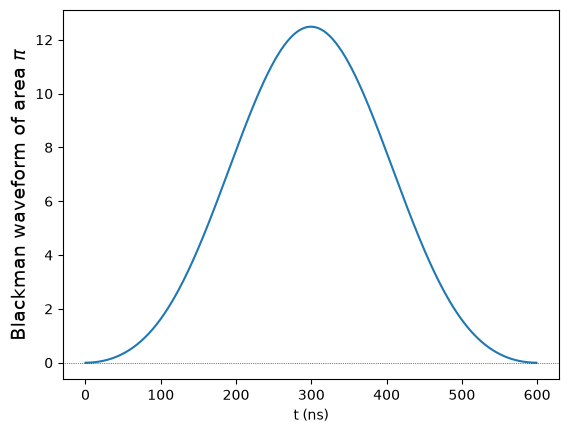

In [11]:
from pulser import Pulse, BlackmanWaveform
from math import pi

pi_wf = BlackmanWaveform(duration=600, area=pi)
print("The integral of the waveform is:", pi_wf.integral)
pi_wf.draw(ylabel='Blackman waveform of area $\\pi$')
pi_pulse = Pulse.ConstantDetuning(amplitude=pi_wf, detuning=0, phase=0)

<font color='Green'> Where we have used a **BlackmanWaveform** for the amplitude, a predefined waveforme profile available in Pulser. </font>

<font color='Green'> Let's add this **Pulse** to **ch0**: </font>

In [12]:
seq.add(pi_pulse, 'ch0')

<font color='Green'> Let's check the pulse schedule to see how it is looking: </font>

In [13]:
print(seq)

Channel: ch0
t: 0 | Initial targets: 0, 1, 2, 3 | Phase Reference: 0.0 
t: 0->600 | Pulse(Amp=Blackman(Area: 3.14) rad/µs, Detuning=0 rad/µs, Phase=0) | Targets: 0, 1, 2, 3




<font color='Green'> For a more visual representation, we can also draw the **Sequence**: </font>

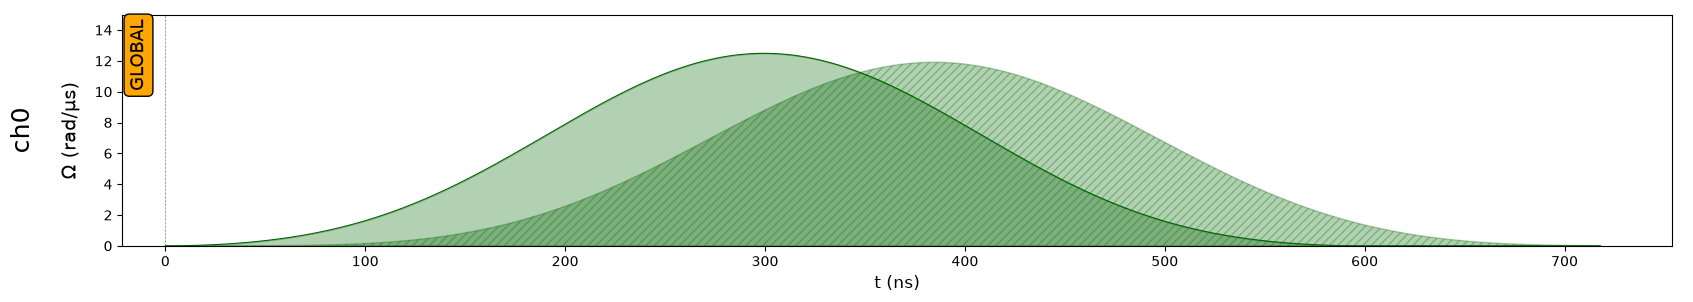

In [14]:
seq.draw(mode="input")

# Step 5 - Measurement

To finish a **Sequence**, we measure it. A measurement signals the end of a **Sequence**, so after it no more changes are possible.

When measuring, one has to select the desired measurement basis. The available options depend on the **Device** and can be consulted by calling ```supported_bases```.

If you only have **Rydberg Channels** and **DMM** available on the **Device**, as it is the case for analog and digital-analog computing, then only the ```ground-rydberg``` basis is available and we work only with the $|r\rangle$ and $|g\rangle$ states.




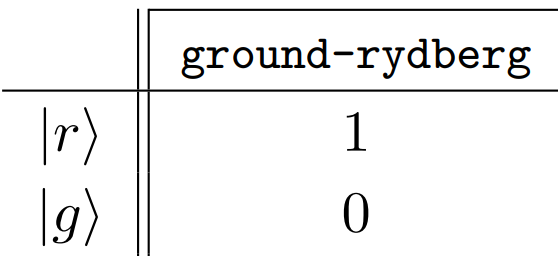

<center> Corresponding measurement outcomes when measuring in the ground-rydberg basis.</center>

<font color='Green'>**Activity 7 - Specifying a measurement basis**</font>

<font color='Green'>In the case of the **AnalogDevice**, only the ```ground-rydberg``` basis is supported:
</font>



In [15]:
AnalogDevice.supported_bases

{'ground-rydberg'}

<font color='Green'>We select it:
</font>



In [16]:
seq.measure(basis='ground-rydberg')

<font color='Green'>And so, we have obtained the final **Sequence** ! One more time, we can visualize it:</font>



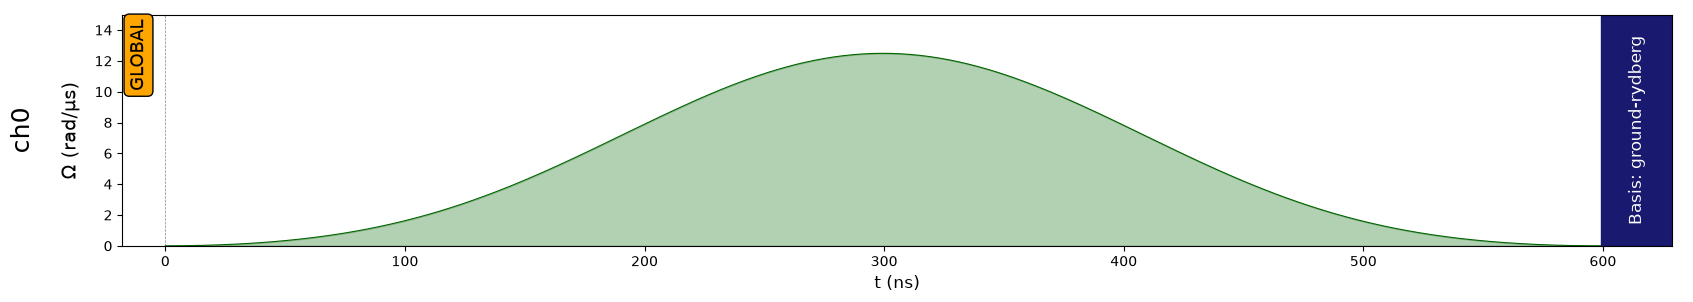

In [20]:
seq.draw(mode="input")

# Step 6 - Simulating the sequence

We have tailored the **Pulse** such that the atoms all go from the ground state (measurement outcome: 0) to the excited state (measurement outcome: 1). But is it really happening ? The **Sequence** can be simulated using a [Backend](https://pulser.readthedocs.io/en/stable/apidoc/_autosummary/pulser.backend.Backend.html#pulser.backend.Backend), a common interface for execution of a **Sequence** using a QPU or an emulator.

Priot to submiting the Sequence to a QPU, it is of good practice (if the number of atoms is not too large) to use an emulator to simulate the outcome of the **Sequence**. A list of all the available emulators is given in [the API](https://pulser.readthedocs.io/en/stable/apidoc/_autosummary/pulser.backend.html). But let's start with emulating a **Sequence** object locally.

<font color='Green'>**Activity 8 - Simulating a Sequence**</font>

<font color='Green'> Pulser comes with ```pulser-simulation```, a package to simulate pulser **Sequence** using the Pyhton library [QuTiP](https://qutip.org/). It implements the ```QutipBackend``` class, a **Backend** that can be initialized with a **Sequence**. The simulation in itself is performed when calling the method ```run```. It solves the Schrödinger's equation associated with the system Hamiltonian using QuTiP solvers, and returns a ```SimulationResults``` object.</font>

<font color='Green'>This ```SimulationResults``` object can be of two kinds:

*   A **NoisyResult** if the simulation involves some kinds of noise
*   A **CoherentResult** in the other cases
</font>

<font color='Green'> Since we are not performing a simulation involving noise here, we get a **CoherentResult**. An array representing the final state of the system of 4 atoms can finally be obtained with ```CoherentResult.get_final_state```:</font>

In [18]:
import pulser_simulation
sim = pulser_simulation.QutipBackend(seq)
res = sim.run()
print(res.get_final_state())

Quantum object: dims=[[2, 2, 2, 2], [1]], shape=(16, 1), type='ket', dtype=Dense
Qobj data =
[[ 9.99995240e-01+0.00000000e+00j]
 [-1.46331250e-03-7.80070384e-06j]
 [-1.46331250e-03-7.80070350e-06j]
 [-3.49034288e-06+4.86356951e-04j]
 [-1.46331250e-03-7.80070350e-06j]
 [-3.49034288e-06+4.86356951e-04j]
 [ 1.73834041e-06+6.08192861e-05j]
 [ 1.31144201e-08-1.14105810e-06j]
 [-1.46331250e-03-7.80070378e-06j]
 [ 1.73834005e-06+6.08192861e-05j]
 [-3.49034314e-06+4.86356951e-04j]
 [ 1.31144229e-08-1.14105836e-06j]
 [-3.49034314e-06+4.86356951e-04j]
 [ 1.31144229e-08-1.14105836e-06j]
 [ 1.31144191e-08-1.14105805e-06j]
 [-4.76932678e-07-5.13092405e-09j]]


/tmp/ipykernel_7227/2922452445.py:2: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(seq)


<font color='Green'> The final state is close to the state where all the atoms are in the excited state, defined by:</font>

$$|rrrr\rangle = \left[ 1, 0 \right]^T \otimes \left[ 1, 0 \right]^T \otimes \left[ 1, 0 \right]^T \otimes \left[ 1, 0 \right]^T = \left[ 1, 0, \dots, 0 \right]^T$$

<font color='Green'>(see the [convention page](https://pulser.readthedocs.io/en/stable/conventions.html) for details). The small difference between the obtained final state and the targeted one is due to the interactions between atoms, a feature we will study in a next lesson. </font>

<font color='Green'>This difference is so small that, when simulating 1000 run of the **Sequence**, the system is always measured in the $|rrrr\rangle$ state:</font>


In [19]:
res.sample_final_state(N_samples=1000)

Counter({'1111': 1000})

<font color='Green'> In all the measurement outcomes, all the atoms are measured in the '1' state. This means they are all always measured in the excited state: the **Sequence** works as intended ! </font>

# Annex: Computing the effect of a Pulse addressing the ground-Rydberg transition on the state of the atoms

## Evolution of a system under an Hamiltonian

The evolution of the state of the system of atoms $\left| \psi(t) \right>$ under an Hamiltonian $H$ is given by the Schrödinger equation:

$$ i \hbar \frac{d\left| \psi(t) \right>}{dt} = H(t)\left| \psi(t) \right>$$

Knowing the initial state at time $t=0$, the state at time $t=\tau > 0$ is given by $e^{-\frac{i}{\hbar} \int_0^{\tau} H(t) \ \text{d}t}\left| \psi(0) \right>$. Where $e^{-\frac{i}{\hbar} \int_0^{\tau} H(t) \ \text{d}t}$ is named the evolution operator.

## Application to the drive Hamiltonian

In this tutorial, we placed ourselves in a specific case where the distance between the atoms in the Register is very large. Therefore the interaction between them is very small and the interaction Hamiltonian can be neglected compared to the drive Hamiltonian, and so $H≈H_D$.

Then, the effect of a `Pulse` of duration $\tau$ on the state of the atom is given by the evolution operator
$$ e^{-\frac{i}{\hbar} \int_0^{\tau} H^D(t) \ \text{d}t} = \exp\left(-i\left(\frac{\int_0^{\tau} \Omega(t) \ \text{d}t}{2} \cos(\phi) \hat{\sigma}_x  - \frac{\int_0^{\tau} \Omega(t) \ \text{d}t}{2} \sin(\phi) \hat{\sigma}_y  - \frac{\int_0^{\tau} \delta(t) \ \text{d}t}{2} \hat{\sigma}_z\right)\right) $$

**Conclusion**: What really matters in the operation is the integral of the amplitude and detuning waveformes along time.



## Tailoring a Pauli X rotation

Initially, the atoms are all in the ground state, such that $\left | \psi(0) \right> = \left |gggg\right>$. To excite the atoms to the state $\left |rrrr\right>$, we have to make an operation involving only the $\hat{\sigma}_x$ operator. This can clearly be seen on the Bloch sphere representation for instance.

This dictates that $\sin(\phi) = 0$ and $\frac{\int_0^{\tau} \delta(t) \ \text{d}t}{2}=0$. The easiest solution is to have $\phi=0$ and $\delta(t)=0$.

With these conditions, the evolution operator applied on each atom is given by $\exp\left(-i\left(\frac{\int_0^{\tau} \Omega(t) \ \text{d}t}{2}\hat{\sigma}_x\right)\right)$.

## Computing the effect of a Pauli X rotation on the state of the atom

A well-known formula for Pauli operators $\hat{\sigma} \in \{\hat{\sigma}_x, \hat{\sigma}_y, \hat{\sigma}_z\}$ is

$$\exp\left(i \theta \hat{\sigma}\right) = \cos(\theta) I + i \sin(\theta) \hat{\sigma} $$

Therefore

$$\exp\left(-i\left(\frac{\int_0^{\tau} \Omega(t) \ \text{d}t}{2}\hat{\sigma}_x\right)\right) = \cos\left(\frac{\int_0^{\tau} \Omega(t) \ \text{d}t}{2}\right) I - i \sin\left(\frac{\int_0^{\tau} \Omega(t) \ \text{d}t}{2}\right)\hat{\sigma}_x$$

The final state is then given by

\begin{align} \left|\psi(\tau)\right> &= \cos\left(\frac{\int_0^{\tau} \Omega(t) \ \text{d}t}{2}\right) \left|\psi(0)\right> - i \sin\left(\frac{\int_0^{\tau} \Omega(t) \ \text{d}t}{2}\right)\hat{\sigma}_x\left|\psi(0)\right> \\
&= \cos\left(\frac{\int_0^{\tau} \Omega(t) \ \text{d}t}{2}\right) \left|gggg\right> - i \sin\left(\frac{\int_0^{\tau} \Omega(t) \ \text{d}t}{2}\right)\left|rrrr\right>\end{align}


As a conclusion, if we want the final state $\left|\psi(\tau)\right>$ to be $\left | rrrr\right>$, it is necessary that

$$\frac{\int_0^{\tau} \Omega(t) \ \text{d}t}{2} = \frac{\pi}{2}\implies\int_0^{\tau} \Omega(t) \ \text{d}t = \pi$$

The `Pulse` in this case is what we call a $\pi$-pulse, a Pulse whose amplitude is of area $\pi$.

